# Future Warming in a Calibrated Simple Climate Model: Active Subspaces of the FaIR v1.4.1 Posterior

__Chris Smith__, School of Earth and Environment, University of Leeds, Leeds, UK; Energy, Climate and Environment Program, International Institute for Applied Systems Analysis (IIASA), Laxenburg, Austria; now at Department of Water and Climate, Vrije Universiteit Brussel, Brussels, Belgium

__Donald P. Cummins__, School of Earth and Environment, University of Leeds, Leeds, UK

__Hege-Beate Fredriksen__, Department of Physics and Technology, UiT the Arctic University of Norway, Tromsø, Norway

__Zebedee Nicholls__, IIASA, Laxenburg, Austria; School of Geography, Earth and Atmospheric Sciences, The University of Melbourne, Melbourne, Australia; Climate Resource, Melbourne, Australia

__Malte Meinshausen__, School of Geography, Earth and Atmospheric Sciences, The University of Melbourne, Melbourne, Australia; Climate Resource, Melbourne, Australia

__Myles Allen__, Atmospheric, Oceanic and Planetary Physics, University of Oxford, Oxford, UK

__Stuart Jenkins__, Atmospheric, Oceanic and Planetary Physics, University of Oxford, Oxford, UK

__Nicholas Leach__, Atmospheric, Oceanic and Planetary Physics, University of Oxford, Oxford, UK

__Camilla Mathison__, School of Earth and Environment, University of Leeds, Leeds, UK; Met Office Hadley Centre, Exeter, UK

__Antti-Ilari Partanen__, Climate System Research, Finnish Meteorological Institute, Helsinki, Finland

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

The notebook runs in Python 3 with numpy, matplotlib and the [active_subspaces](https://github.com/paulcon/active_subspaces) library (version 1.0 or later) and reads the shipped files. In the repository's terms this is a **stored-data** set. The 841 parameter sets are the published v1.4.1 posterior (converted losslessly by `convert_data.py`). The model outputs and gradients were computed for this repository with [FaIR](https://github.com/OMS-NetZero/FAIR) 2.1.3, an outside code, by `generate_data.py` and `fair_driver.py`. The shipped files are the record, and `DATA.md` gives the full provenance. FaIR is needed only to regenerate them.

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac
import fair_driver as fd   # names, units, coordinate changes and file loaders (numpy only); running FaIR needs fair 2.1.3

SEED = 2024                # the only seed in this notebook (bootstrap)
t_start = time.perf_counter()
QN = fd.QOI_NAMES          # dT_ssp245_2081-2100, ECS, TCR, GMST_2003-2022
QLAB = {'dT_ssp245_2081-2100': r'$\Delta T_{2081-2100}$, SSP2-4.5 (K)', 'ECS': 'ECS (K)', 'TCR': 'TCR (K)',
        'GMST_2003-2022': 'GMST 2003-2022 (K)'}
GCOL = {'climate response': 'C0', 'carbon cycle': 'C2', 'aerosol-radiation': 'C1', 'aerosol-cloud': 'C3',
        'ozone': 'C4', 'forcing scaling': 'C7'}

### Summary

FaIR is an emission-driven simple climate model, and fair-calibrate v1.4.1 constrains 45 of its parameters to an 841-member posterior that reproduces historical warming and assessed climate metrics. With deterministic FaIR 2.1.3 runs of that posterior under SSP2-4.5 and finite-difference gradients, the gradient-based active subspace of the 2081–2100 warming has $\lambda_1/\lambda_2 = 4.9$ and needs four dimensions before a quadratic reaches a 10-fold cross-validated $R^2$ of 0.917, while a quadratic in the single least-squares direction of the same whitened inputs (mostly the feedback $\kappa_1$ and the present-day aerosol–cloud forcing) also reaches 0.917 and one in $\mathbf w_1$ only 0.635: the warming is close to a one-dimensional ridge that the leading eigenvector does not find, whereas ECS is nearly one-dimensional ($\lambda_1/\lambda_2 = 89.7$) and $\mathbf w_1$ finds it. On this multimodal, heavy-tailed posterior the gradient matrix is dominated by large local gradients near the switch-on of the aerosol–cloud shape parameters, so its eigenvalues need not rank directions by how much the warming varies across the posterior, and the result also depends on how the aerosol–cloud forcing is parametrized: with its scale $\beta$ as an input instead of the 2005–2014 forcing that sets it in the paper's prior, the leading direction explains none of the warming.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$, with the gradient taken in normalized coordinates. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend, and a low-degree polynomial in $\mathbf y$ can stand in for $f$. Here the inputs are correlated, so the normalized coordinates are whitened ones (below), and $\mathbf C$ is the sample average of gradient outer products over the posterior ensemble, assessed with the bootstrap. See P. G. Constantine, [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860), SIAM, 2015.

### The model

FaIR is an emission-driven simple climate model. Emissions of about 50 species drive gas cycles, the gases and aerosols give effective radiative forcings, and the forcing drives a three-layer energy balance model. The paper writes the energy balance as [1, pp. 8572–8573, Eqs. 1–4]

$$
C_1\frac{dT_1}{dt} = F(t) - \kappa_1T_1 - \kappa_2(T_1-T_2) + \xi(t),\qquad
C_2\frac{dT_2}{dt} = \kappa_2(T_1-T_2) - \varepsilon\kappa_3(T_2-T_3),\qquad
C_3\frac{dT_3}{dt} = \kappa_3(T_2-T_3),
$$

with $F = F_{\rm det} + \zeta$ and $d\zeta/dt = -\gamma\zeta + \eta$ (Eq. 4), where $\xi$ and $\eta$ are white noise with standard deviations $\sigma_\xi$ and $\sigma_\eta$ (p. 8573). $F_{4\times}$, the forcing of quadrupled CO$_2$, "is not used in the climate response of FaIR but is used in the theoretical calculation of ECS and TCR" (p. 8580). The aerosol–cloud forcing is $\mathrm{ERF_{aci}} = \beta\left[\log\left(1 + \sum_i s_iA_i\right) - \log\left(1 + \sum_i s_iA_{i,\rm base}\right)\right]$ over SO$_2$, BC and OC emissions (Eq. 8, p. 8578). The CO$_2$ lifetime is scaled through the 100-year integrated airborne fraction $I_{100} = r_0 + r_U\Delta C_U + r_T\Delta T + r_A\Delta C_A$ (Eq. 7, p. 8577). Aerosol–radiation and ozone forcings are linear in their precursors (Tables 3 and 4), and the other forcings carry scale factors (Table 5). The methane lifetime calibration (Table 1, p. 8577), the land-use and snow-albedo factors, and the 1750 baseline emissions are fixed at the v1.4.1 values.

**FaIR 2.1.3 differs from the printed Eq. 4 in one respect that matters here.** In its code (`energy_balance_model.py`), the first state variable relaxes towards the forcing at rate $\gamma$, $\dot s = -\gamma(s - F)$, and the surface layer is forced by $s$, so $\gamma$ sets a lag of $1/\gamma$ years even when internal variability is off. In the printed equations, $\zeta$ stays 0 when $\eta = 0$, and the paper says that Eqs. (1)–(4) then "reduce to a deterministic energy balance model" (p. 8573), in which $\gamma$ would have no effect. This data set uses FaIR as it runs.

**Quantities of interest** (the paper's Table 6 definitions, p. 8585; means over time bounds with half weights at the ends, as in fair-calibrate):

1. $\Delta T_{2081-2100}$: global mean surface temperature (GMST) 2081–2100 relative to 1995–2014 under SSP2-4.5, with the SSP emissions harmonised to the 2022 historical emissions (the v1.4.1 projections, p. 8575). This is the main QoI.
2. ECS and 3. TCR of the energy balance model, from its impulse-response coefficients (p. 8574). They depend only on $C_{1..3}$, $\kappa_{1..3}$, $\varepsilon$ and $F_{4\times}$.
4. GMST 2003–2022 relative to 1850–1900, the historical warming used as a constraint (Table 6).

**Internal variability.** The paper runs FaIR with internal variability on and one fixed seed per parameter set (p. 8580). A QoI that contains a different noise realization in every member is not a function of the parameters alone, so the subspace is computed from **deterministic runs** (internal variability off); the runs with each member's seed are shipped too and are used to check the set-up against Table 6. With internal variability off, $\sigma_\eta$ and $\sigma_\xi$ do not enter the model.

**Inputs.** "In total, 45 parameters are sampled" (p. 8580). The paper lists them in its supplement Table S3, which was not available for this notebook; the list below is the column list of the published posterior file, which has 45 parameter columns, and the sources are the paper's sections and tables. The posterior is the set of 841 members selected in the reweighting step (Sect. 3.3.2, p. 8582), from a 1.6-million-member Monte Carlo prior (p. 8578) of which 224 342 pass the historical-warming filter (p. 8581). It is a correlated, non-Gaussian sample, not a box; this notebook gives each member equal weight. The table prints the posterior 5 %, 50 % and 95 % values and the coordinate each parameter has in the analysis (next sections).

In [2]:
SOURCE = {'climate response': 'Sect. 3.2.1, p. 8580 (11-D KDE of 49 CMIP6 fits)',
          'carbon cycle': 'Sect. 3.2.4, p. 8580 (4-D KDE of 11 models; CO2 1750 Gaussian 278.3 +/- 2.9 ppm)',
          'aerosol-radiation': 'Sect. 3.2.3 and Table 3, pp. 8580-8581 (Gaussian, scaled to AR6)',
          'aerosol-cloud': 'Sect. 3.2.2, p. 8580; Table 2, p. 8579 (KDE of log s; beta from a trapezoid ERFaci)',
          'ozone': 'Sect. 3.2.5 and Table 4, pp. 8580-8582 (Gaussian)', 'forcing scaling': 'Sect. 3.2.6 and Table 5, pp. 8581-8582'}
ids, X, seeds = fd.load_posterior()
q5, q50, q95 = np.percentile(X, [5, 50, 95], axis=0)
print(f"{'#':>2s} {'name in FaIR / fair-calibrate':48s} {'units':24s} {'5 %':>11s} {'median':>11s} {'95 %':>11s}  coordinate v")
for j, (n, u, g) in enumerate(zip(fd.PARAM_NAMES, fd.UNITS, fd.GROUP)):
    coord = 'ln x' if j in fd.LOG_IDX else ('ERFaci 2005-2014 = beta D(s)' if j == fd.BETA_IDX else 'x')
    print(f'{j:2d} {n:48s} {u:24s} {q5[j]:11.3e} {q50[j]:11.3e} {q95[j]:11.3e}  {coord}')
print()
for g, s in SOURCE.items():
    print(f'{g:18s} ({fd.GROUP.count(g):2d} parameters): {s}')
print(f'\nm = {fd.M_PARAMS} sampled parameters; posterior members: {len(X)}')

 # name in FaIR / fair-calibrate                    units                            5 %      median        95 %  coordinate v
 0 clim_gamma                                       yr-1                       1.239e+00   5.910e+00   1.879e+01  x
 1 clim_c1                                          W yr m-2 K-1               2.428e+00   4.130e+00   5.771e+00  x
 2 clim_c2                                          W yr m-2 K-1               6.664e+00   1.721e+01   3.314e+01  x
 3 clim_c3                                          W yr m-2 K-1               3.145e+01   8.540e+01   1.776e+02  x
 4 clim_kappa1                                      W m-2 K-1                  7.700e-01   1.298e+00   1.965e+00  x
 5 clim_kappa2                                      W m-2 K-1                  1.111e+00   2.447e+00   4.732e+00  x
 6 clim_kappa3                                      W m-2 K-1                  3.523e-01   1.156e+00   2.579e+00  x
 7 clim_epsilon                                     1        

### Load data

`posterior_parameters.csv` holds the 841 posterior members (their prior-ensemble index, the 45 parameters in physical units, and the seed). `qoi.csv` holds the four QoIs from deterministic FaIR runs and the CO$_2$ concentration in 2022; `qoi_internal_variability.csv` holds the same from runs with each member's own seed. `gradients_<qoi>.csv` holds the gradient of each QoI with respect to the coordinates $u$ (below), by central differences with a step of $10^{-3}$ posterior standard deviations of each $u_j$ (checked in `DATA.md`). The notebook converts them to the coordinates $v$ by the chain rule.

In [3]:
ids, X, seeds = fd.load_posterior()                      # (841,), (841, 45) physical units, (841,) seeds
Q = np.loadtxt(fd.F_QOI, delimiter=',')                   # (841, 6): id, 4 QoIs (K), CO2 2022 (ppm); deterministic
Qiv = np.loadtxt(fd.F_QOI_IV, delimiter=',')              # (841, 6): the same with internal variability
Gu = {q: np.loadtxt(fd.GRAD_FILES[q], delimiter=',') for q in QN}   # (841, 45) df/du_j, u = fd.to_analysis(X)
F = {q: Q[:, k + 1] for k, q in enumerate(QN)}
Fiv = {q: Qiv[:, k + 1] for k, q in enumerate(QN)}
assert (Q[:, 0] == ids).all() and (Qiv[:, 0] == ids).all()
for name, a in [('X', X), ('Q', Q), ('Qiv', Qiv)] + [(f'Gu[{q}]', Gu[q]) for q in QN]:
    print(f'{name:24s} {a.shape}')

X                        (841, 45)
Q                        (841, 6)
Qiv                      (841, 6)
Gu[dT_ssp245_2081-2100]  (841, 45)
Gu[ECS]                  (841, 45)
Gu[TCR]                  (841, 45)
Gu[GMST_2003-2022]       (841, 45)


**Check against the paper.** The runs with internal variability use the paper's seeds, so their percentiles should match the reweighted posterior of Table 6 (p. 8585). The SSP2-4.5 emission file was rebuilt for this data set from the fair-calibrate v1.4.1 inputs (the paper's own file was not available here: the 3.8 GB archive of its Zenodo record was not downloaded; `DATA.md`), so the SSP2-4.5 row also checks that reconstruction.

In [4]:
# paper Table 6, p. 8585: reweighted posterior 5 %, 50 %, 95 %
T6 = {'dT_ssp245_2081-2100': (1.06, 1.71, 2.66), 'ECS': (2.01, 2.96, 4.99), 'TCR': (1.31, 1.79, 2.38),
      'GMST_2003-2022': (0.86, 1.03, 1.13), 'CO2_2022': (416.1, 417.0, 417.8)}
Fiv['CO2_2022'], F['CO2_2022'] = Qiv[:, 5], Q[:, 5]
print(f"{'quantity':22s} {'Table 6':>20s} {'with variability':>24s} {'deterministic':>24s}")
for q, t in T6.items():
    a, b = np.percentile(Fiv[q], [5, 50, 95]), np.percentile(F[q], [5, 50, 95])
    print(f'{q:22s} {str(t):>20s}   ' + ' '.join(f'{v:7.3f}' for v in a) + '   ' + ' '.join(f'{v:7.3f}' for v in b))
d = {q: Fiv[q] - F[q] for q in ['dT_ssp245_2081-2100', 'GMST_2003-2022']}
for q, v in d.items():
    print(f'{q}: internal variability minus deterministic, mean {v.mean():+.4f} K, sd {v.std(ddof=1):.4f} K')

quantity                            Table 6         with variability            deterministic
dT_ssp245_2081-2100      (1.06, 1.71, 2.66)     1.064   1.706   2.658     1.078   1.711   2.682
ECS                      (2.01, 2.96, 4.99)     2.012   2.964   4.987     2.012   2.964   4.987
TCR                      (1.31, 1.79, 2.38)     1.312   1.795   2.377     1.312   1.795   2.377
GMST_2003-2022           (0.86, 1.03, 1.13)     0.859   1.027   1.132     0.849   1.016   1.151
CO2_2022               (416.1, 417.0, 417.8)   416.138 417.034 417.834   416.084 417.006 417.953
dT_ssp245_2081-2100: internal variability minus deterministic, mean -0.0034 K, sd 0.0645 K
GMST_2003-2022: internal variability minus deterministic, mean +0.0074 K, sd 0.0549 K


With internal variability on and the paper's seeds, the 5 %, 50 % and 95 % values agree with Table 6 to within 0.005 K for all four temperatures (ECS 2.012, 2.964, 4.987 against 2.01, 2.96, 4.99; SSP2-4.5 warming 1.064, 1.706, 2.658 against 1.06, 1.71, 2.66) and to within 0.04 ppm for CO$_2$ in 2022, which also confirms the rebuilt SSP2-4.5 emissions. The deterministic runs give the same ECS and TCR, and a wider GMST 2003–2022 range (0.849 to 1.151 K against 0.859 to 1.132 K): the reweighting favoured members whose own noise realization fits the observations. Switching internal variability off changes a member's SSP2-4.5 warming by −0.0034 K on average, with a standard deviation of 0.0645 K.

**Checks of the gradients and samples.** ECS has a closed form, $F_{4\times}/(2\kappa_1)$, since at equilibrium $T_1 = T_2 = T_3$ and Eq. (1) gives $T_1 = F/\kappa_1$ with $F = F_{4\times}/2$. Its gradient is a test of the finite differences.

In [5]:
# ECS of the three-layer model is F4x / (2 kappa1) (equilibrium: T1 = F / kappa1 from Eq. 1 with T1 = T2 = T3)
k1, F4 = X[:, fd.PARAM_NAMES.index('clim_kappa1')], X[:, fd.PARAM_NAMES.index('clim_F_4xCO2')]
ecs_cf = F4 / (2 * k1)
print(f'ECS from FaIR vs F4x/(2 kappa1): max relative difference {np.max(np.abs(F["ECS"] / ecs_cf - 1)):.1e}')
g_cf = np.zeros_like(Gu['ECS'])
g_cf[:, fd.PARAM_NAMES.index('clim_kappa1')] = -F4 / (2 * k1**2)
g_cf[:, fd.PARAM_NAMES.index('clim_F_4xCO2')] = 1 / (2 * k1)
err = np.linalg.norm(Gu['ECS'] - g_cf, axis=1) / np.linalg.norm(g_cf, axis=1)
print(f'ECS gradient, finite differences vs the closed form: relative 2-norm error median {np.median(err):.1e}, '
      f'max {err.max():.1e}')
dep = {q: [fd.SHORT[j] for j in range(45) if np.any(Gu[q][:, j] != 0)] for q in ['ECS', 'TCR']}
print('inputs with any nonzero stored gradient: ECS', dep['ECS'], '; TCR', dep['TCR'])
idle = [j for j in range(45) if all(np.all(Gu[q][:, j] == 0) for q in QN)]
print('inputs whose stored gradients are zero for all four QoIs:', [fd.SHORT[j] for j in idle])
print('dT gradient with respect to F4xCO2: max |.|', f"{np.abs(Gu['dT_ssp245_2081-2100'][:, 10]).max():.1e} K / W m-2")
g_gam = Gu['dT_ssp245_2081-2100'][:, 0]
print(f'dT gradient with respect to gamma: nonzero in {np.sum(g_gam != 0)} members, median {np.median(g_gam):+.1e} K yr')
print('samples outside physical meaning (C, kappa, epsilon, F4x, s_i <= 0; CO2_1750 <= 0):',
      int(np.sum(np.any(X[:, [1, 2, 3, 4, 5, 6, 7, 10, 24, 25, 26, 44]] <= 0, axis=1))))
print(f'duplicate rows: {len(X) - len(np.unique(X, axis=0))}; aci_beta > 0 in {np.sum(X[:, 27] > 0)} members')

ECS from FaIR vs F4x/(2 kappa1): max relative difference 4.0e-15
ECS gradient, finite differences vs the closed form: relative 2-norm error median 7.9e-08, max 5.2e-07
inputs with any nonzero stored gradient: ECS ['C1', 'C2', 'C3', 'kappa1', 'kappa2', 'kappa3', 'epsilon', 'F4xCO2'] ; TCR ['C1', 'C2', 'C3', 'kappa1', 'kappa2', 'kappa3', 'epsilon', 'F4xCO2']
inputs whose stored gradients are zero for all four QoIs: ['sigma_eta', 'sigma_xi', 'ari_EESC']
dT gradient with respect to F4xCO2: max |.| 0.0e+00 K / W m-2
dT gradient with respect to gamma: nonzero in 841 members, median -3.8e-04 K yr
samples outside physical meaning (C, kappa, epsilon, F4x, s_i <= 0; CO2_1750 <= 0): 0
duplicate rows: 0; aci_beta > 0 in 4 members


ECS from FaIR equals $F_{4\times}/(2\kappa_1)$ to rounding (relative difference of order 1e-15), and the finite-difference ECS gradient matches the closed form with a median relative error of 7.9e-08 (maximum 5.2e-07). ECS and TCR have nonzero stored gradients only with respect to the eight energy-balance parameters $C_{1..3}$, $\kappa_{1..3}$, $\varepsilon$ and $F_{4\times}$; for ECS, the components with respect to all of them but $\kappa_1$ and $F_{4\times}$ are finite-difference rounding. The stored gradients with respect to $\sigma_\eta$, $\sigma_\xi$ and ari_EESC are zero for all four QoIs. For $\sigma_\eta$ and $\sigma_\xi$ this is because internal variability is off. For ari_EESC it is a property of FaIR 2.1.3, the version the paper also runs (p. 8570): within each time step, its `fair.py` computes the aerosol–radiation forcing (its step 6) before it computes the EESC concentration of that step (step 8), so the EESC value the forcing reads is still unset (NaN), and the sum over species (`np.nansum`) drops the term. The parameter therefore has no effect in FaIR 2.1.3 runs, the paper's included, not only in this set-up. The SSP2-4.5 warming has a zero stored gradient with respect to $F_{4\times}$ in every member (as p. 8580 says, it is not used in the climate response), but a nonzero one with respect to $\gamma$ in all 841 members (median −3.8e-04 K yr), as FaIR's code implies. No member lies outside physical meaning, no row is duplicated, and $\beta > 0$ in 4 members.

### The input space

The posterior is correlated. The prior samples the components of FaIR (climate response, carbon cycle, aerosols, …) independently and keeps the correlations only within each component (p. 8578); correlations across components, such as that of ERFaci with $\kappa_1$, come from the constraints. Several parameters span orders of magnitude, and some of its marginals are multimodal (Fig. 10, p. 8586). This data set makes three choices, which are its own, not the paper's.

1. **Coordinates $u$ (those of the stored gradients).** The three aerosol–cloud shape parameters $s_{\rm SO_2}, s_{\rm BC}, s_{\rm OC}$ enter as $\ln s$, the coordinate of the paper's kernel density estimate (Sect. 3.2.2, p. 8580); the scale $\beta$ enters as $\operatorname{asinh}(\beta/1\,\mathrm{W\,m^{-2}})$, logarithmic for $|\beta|\gg1$ and linear near 0. The other 41 parameters are used as they are.
2. **Coordinates $v$ (those of the analysis).** In the prior, $\beta$ is not drawn on its own: the unscaled ERFaci of 2005–2014 is "scaled to reproduce a draw from a trapezoid distribution ... which selects the $\beta$ value to use for that parameter set" (Sect. 3.2.2, p. 8580). So $v$ is $u$ with $\operatorname{asinh}\beta$ replaced by that forcing, $\mathrm{ERFaci}_{2005-2014} = \beta\,D(s)$, where $D(s)$ is the mean over the emission years 2005–2014 of $\log(1+\sum_i s_iA_i) - \log(1+\sum_i s_iA_{i,\rm 1750})$ (Eq. 8, p. 8578), computed from the shipped emission file (`fd.erfaci_unscaled`). At fixed ERFaci, a change of $\ln s_i$ changes only the time shape of the aerosol–cloud forcing, not its present-day size. The gradients in $v$ follow from the stored ones by the chain rule (`fd.to_erfaci_coordinates`). The section "Why not $\beta$ itself" shows what the coordinates $u$ give.
3. **Whitening.** All 45 coordinates are scaled the same way, through one Gaussian approximation of the posterior of $v$: `ac.Gaussian(mean, cov)` with the sample mean and covariance of the 841 members, i.e. $z = L^{-1}(v - \bar v)$ with $\Sigma = LL^T$ (Cholesky). The Gaussian only defines the linear map; the expectation in $\mathbf C$ is the average over the 841 members, not over a Gaussian. Eigenvalues, the subspace in $v$, and the loadings below do not depend on the choice of factor $L$; the components of $\mathbf w$ in $z$ do, so they are not plotted. The loadings are the correlations $\operatorname{corr}(v_i, y_k)$ with $y_k = \mathbf w_k^T z$, i.e. $(L\mathbf w_k)_i/\sigma_i$.

In [6]:
U = fd.to_analysis(X)                                     # u: ln s for the shape parameters, asinh(beta)
V, Gv = {}, {}
for q in QN:
    V, Gv[q] = fd.to_erfaci_coordinates(X, Gu[q])         # v: beta replaced by ERFaci 2005-2014 (chain rule)
erfaci = V[:, fd.BETA_IDX]
Dd = fd.erfaci_unscaled(X)[0]
print(f'D(s) > 0 in all members: {bool(np.all(Dd > 0))} (range {Dd.min():.1e} to {Dd.max():.2f})')
pe = np.percentile(erfaci, [5, 50, 95])
print('ERFaci 2005-2014 (W m-2) 5/50/95 %:', np.array2string(pe, precision=4),
      f'| Table 6 (p. 8585): -1.66, -0.96, -0.35; largest difference {np.abs(pe - [-1.66, -0.96, -0.35]).max():.4f} W m-2')
print(f'beta ranges from {X[:, fd.BETA_IDX].min():.3g} to {X[:, fd.BETA_IDX].max():.3g} W m-2; '
      f's_BC from {X[:, 25].min():.1e} to {X[:, 25].max():.1e}')
spaces = {}
for key, W_ in (('v', V), ('u', U)):
    spaces[key] = ac.Gaussian(W_.mean(axis=0), np.cov(W_.T), names=fd.SHORT_V if key == 'v' else fd.SHORT)
space = spaces['v']                                        # the main coordinates
Z = space.to_normalized(V)
sk, ku = np.mean(Z**3, axis=0), np.mean(Z**4, axis=0)
R = np.corrcoef(V.T)
print(f'whitened coordinates: max |mean z| {np.abs(Z.mean(0)).max():.1e}, max |cov(z) - I| {np.abs(np.cov(Z.T) - np.eye(45)).max():.1e}')
print(f'skewness of z_j: {sk.min():+.2f} to {sk.max():+.2f}; kurtosis {ku.min():.2f} to {ku.max():.2f} (Gaussian 0 and 3)')
print(f'correlation matrix of v: eigenvalues {np.linalg.eigvalsh(R).min():.1e} to {np.linalg.eigvalsh(R).max():.2f}')
iu = np.triu_indices(45, 1)
top = np.argsort(-np.abs(R[iu]))[:6]
print('largest correlations:', '; '.join(f'{fd.SHORT_V[iu[0][t]]}-{fd.SHORT_V[iu[1][t]]} {R[iu][t]:+.3f}' for t in top))
# gradient coordinates: least-squares slope of f on z against the mean whitened gradient, in v and in u
for key, W_, G_ in (('v', V, Gv), ('u', U, Gu)):
    Zk = spaces[key].to_normalized(W_)
    for q in QN:
        b = np.linalg.lstsq(np.c_[np.ones(len(Zk)), Zk], F[q], rcond=None)[0][1:]
        gb = spaces[key].grads_to_normalized(G_[q]).mean(0)
        print(f'{key}: {q:20s} OLS slope vs mean whitened gradient: cosine {b @ gb / np.linalg.norm(b) / np.linalg.norm(gb):.3f}, '
              f'norms {np.linalg.norm(b):.3f} and {np.linalg.norm(gb):.3f} K')

D(s) > 0 in all members: True (range 2.3e-05 to 2.50)
ERFaci 2005-2014 (W m-2) 5/50/95 %: [-1.6627 -0.9592 -0.3436] | Table 6 (p. 8585): -1.66, -0.96, -0.35; largest difference 0.0064 W m-2
beta ranges from -4.31e+04 to 932 W m-2; s_BC from 4.1e-94 to 5.1e+09
whitened coordinates: max |mean z| 6.7e-13, max |cov(z) - I| 1.2e-12
skewness of z_j: -1.24 to +3.35; kurtosis 2.11 to 26.98 (Gaussian 0 and 3)
correlation matrix of v: eigenvalues 1.5e-04 to 3.33
largest correlations: F4xCO2-fs_CO2 +1.000; r0-rU -0.940; rT-rA -0.873; gamma-sigma_eta +0.803; r0-rA +0.724; rU-rA -0.719
v: dT_ssp245_2081-2100  OLS slope vs mean whitened gradient: cosine 0.890, norms 0.464 and 0.637 K
v: ECS                  OLS slope vs mean whitened gradient: cosine 0.995, norms 0.887 and 0.986 K
v: TCR                  OLS slope vs mean whitened gradient: cosine 0.939, norms 0.304 and 0.380 K
v: GMST_2003-2022       OLS slope vs mean whitened gradient: cosine 0.638, norms 0.078 and 0.199 K
u: dT_ssp245_2081-2100  

$D(s)$ is positive in every member (2.3e-05 to 2.50), so $v$ is a valid change of coordinates, and the posterior 5 %, 50 % and 95 % values of the new coordinate, −1.6627, −0.9592 and −0.3436 W m$^{-2}$, agree with the ERFaci of Table 6 (−1.66, −0.96, −0.35, p. 8585) to within 0.0064 W m$^{-2}$ (the 95 % value rounds to −0.34, not −0.35): it is the forcing the paper reports. The whitened coordinates have skewness from −1.24 to +3.35 and kurtosis from 2.11 to 26.98, so the posterior is far from Gaussian; $F_{4\times}$ and the CO$_2$ forcing scale have correlation +1.000 to the printed digits, because the paper maps one onto the other by quantiles (Sect. 3.2.6, p. 8581). The last lines compare two vectors that would be equal if $z$ were standard Gaussian (Stein's identity, $E[f\,z] = E[\nabla_z f]$): the least-squares slope of $f$ on $z$ and the mean whitened gradient. In $v$ they nearly agree for ECS (cosine 0.995, norms 0.887 and 0.986 K) but not for the SSP2-4.5 warming (cosine 0.890, norms 0.464 and 0.637 K) or TCR (0.939), and not at all for GMST 2003–2022 (0.638; 0.078 and 0.199 K); in $u$, the cosines for the warming and GMST drop to 0.441 and 0.020. The gaps measure how far this posterior is from the Gaussian measure that the usual active-subspace error bounds assume, and they recur below: the gradients average to more than the variation of $f$ across the posterior.

### Estimate the subspace

Gradients are available for every member, so we use the gradient estimator (`estimator="as"`), $\hat{\mathbf C} = \frac1M\sum_i\nabla_z f_i\nabla_z f_i^T$ with $M = 841$, and 500 bootstrap replicates (seed `SEED`). Signs: the paper has no active-subspace results, so `ac.orient(by="covariance")` makes each QoI increase along each of $\mathbf w_1, \dots, \mathbf w_4$ (positive covariance of $f$ with $y_k$); the subspace is returned with four columns, and the dimension is chosen in the results. The cell prints the leading eigenvalues, their ratios, the trace shares, and the dimension the library's eigenvalue-gap rule picks.

In [7]:
def fmt_ratio(r):
    return f'{r:9.2f}' if r < 1e4 else f'{r:9.1e}'
sub = {}
for q in QN:
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        s = ac.active_subspace(space=space, X=V, f=F[q], grads=Gv[q], estimator='as', n=4, nboot=500, rng=SEED)
    sub[q] = ac.orient(s, by='covariance', X=V, f=F[q], columns=4)   # sign: f increases along w1, ..., w4
    lam = sub[q].eigenvalues
    k_hat = ac.dimension_criterion(sub[q], rule='evg')[2]
    print(f'{q:20s} lambda1..4 {np.array2string(lam[:4], precision=3)}; ratios l1/l2, l2/l3, l3/l4:'
          + ''.join(fmt_ratio(lam[i] / lam[i + 1]) for i in range(3))
          + f'; l1/trace {lam[0] / lam.sum():.3f}, (l1+l2)/trace {(lam[0] + lam[1]) / lam.sum():.3f}; gap rule n = {k_hat}')

dT_ssp245_2081-2100  lambda1..4 [0.52  0.107 0.075 0.063]; ratios l1/l2, l2/l3, l3/l4:     4.86     1.44     1.19; l1/trace 0.662, (l1+l2)/trace 0.798; gap rule n = 1


ECS                  lambda1..4 [1.375e+00 1.533e-02 7.310e-24 6.103e-24]; ratios l1/l2, l2/l3, l3/l4:    89.70  2.1e+21     1.20; l1/trace 0.989, (l1+l2)/trace 1.000; gap rule n = 1


TCR                  lambda1..4 [0.172 0.034 0.018 0.003]; ratios l1/l2, l2/l3, l3/l4:     5.09     1.86     6.95; l1/trace 0.755, (l1+l2)/trace 0.903; gap rule n = 1


GMST_2003-2022       lambda1..4 [0.127 0.056 0.01  0.007]; ratios l1/l2, l2/l3, l3/l4:     2.26     5.49     1.46; l1/trace 0.608, (l1+l2)/trace 0.877; gap rule n = 1


For the SSP2-4.5 warming, $\lambda_1 = 0.52$ carries 0.662 of the trace and $\lambda_1/\lambda_2 = 4.86$; the next two ratios, 1.44 and 1.19, are comparable. ECS has $\lambda_1/\lambda_2 = 89.70$ and a drop of about 21 orders of magnitude after $\lambda_2$, since it depends on $\kappa_1$ and $F_{4\times}$ only. TCR has $\lambda_1/\lambda_2 = 5.09$ and GMST 2003–2022 only 2.26. The library's eigenvalue-gap rule picks $n = 1$ for all four QoIs; the dimension of the warming subspace is chosen below.

### Results

**Eigenvalues** with 95 % bootstrap bands, for the four QoIs (the dotted line marks the four columns returned). The warming and GMST panels show the range of the first 12 eigenvalues so that the bands are visible; the cell prints the smallest eigenvalue of each QoI.

dT_ssp245_2081-2100  lambda_i/lambda_1, i = 2..6: [0.2059 0.1433 0.1207 0.0229 0.0063]; smallest 6e-33
ECS                  lambda_i/lambda_1, i = 2..6: [1.1148e-02 5.3176e-24 4.4398e-24 2.5399e-24 2.0995e-24]; smallest 5e-34
TCR                  lambda_i/lambda_1, i = 2..6: [0.1963 0.1057 0.0152 0.0046 0.0026]; smallest 3e-33
GMST_2003-2022       lambda_i/lambda_1, i = 2..6: [0.4427 0.0806 0.0553 0.0385 0.0174]; smallest 5e-33


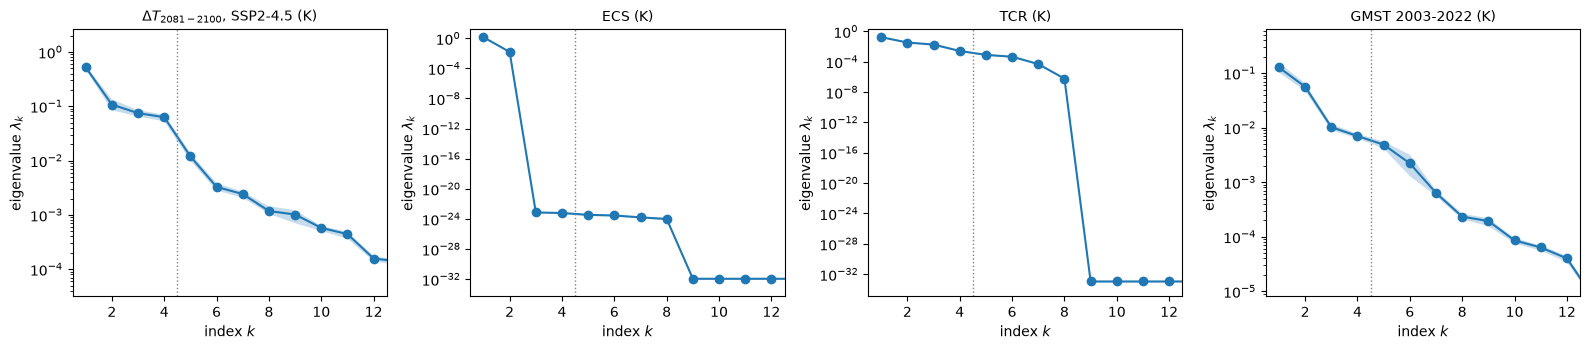

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, q in zip(axes, QN):
    ac.plotting.plot_eigenvalues(sub[q], ax=ax)
    ax.set_title(QLAB[q], fontsize=10)
    ax.set_xlim(0.5, 12.5)
    if q in ('dT_ssp245_2081-2100', 'GMST_2003-2022'):
        ax.set_ylim(sub[q].eigenvalues[11] / 5, sub[q].eigenvalues[0] * 5)
fig.tight_layout(); plt.close(fig)
for q in QN:
    lam = sub[q].eigenvalues
    print(f'{q:20s} lambda_i/lambda_1, i = 2..6: {np.array2string((lam / lam[0])[1:6], precision=4)}; '
          f'smallest {lam[-1] / lam[0]:.0e}')
fig

The warming's spectrum falls after the first eigenvalue and again after the fourth ($\lambda_4/\lambda_1 = 0.1207$, $\lambda_5/\lambda_1 = 0.0229$). ECS falls after two eigenvalues to $\lambda_3/\lambda_1$ of order 1e-24, the size of the squared finite-difference rounding in the components on which ECS does not depend. TCR's eigenvalues after its eight inputs with nonzero gradients are at the rounding level (the smallest of order 1e-33 of $\lambda_1$), and GMST 2003–2022 decays slowly with no clear gap (ratios to $\lambda_1$ of 0.4427, 0.0806, 0.0553).

dT_ssp245_2081-2100  bootstrap mean subspace distance, n = 1..4: [0.045 0.164 0.281 0.042]
ECS                  bootstrap mean subspace distance, n = 1..4: [5.761e-03 2.100e-12 3.320e-01 1.806e-01]
TCR                  bootstrap mean subspace distance, n = 1..4: [0.026 0.083 0.029 0.039]
GMST_2003-2022       bootstrap mean subspace distance, n = 1..4: [0.051 0.034 0.085 0.139]


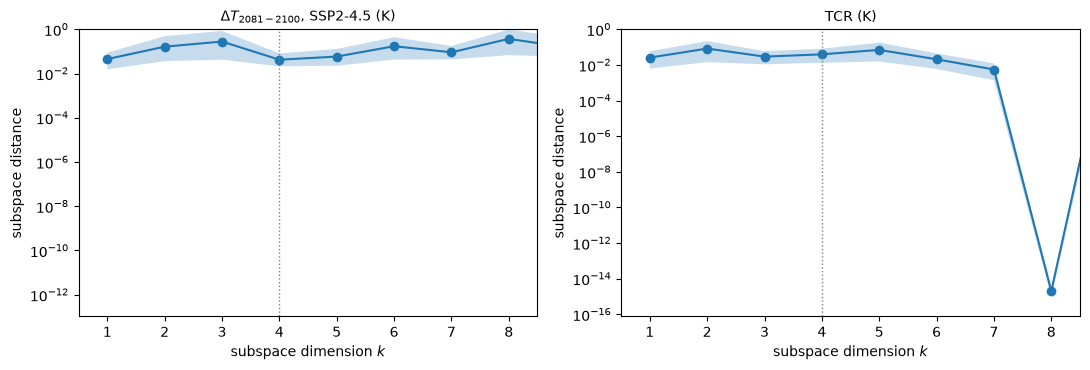

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, q in zip(axes, ['dT_ssp245_2081-2100', 'TCR']):
    ac.plotting.plot_subspace_errors(sub[q], ax=ax)
    ax.set_title(QLAB[q], fontsize=10); ax.set_xlim(0.5, 8.5)
fig.tight_layout(); plt.close(fig)
for q in QN:
    print(f'{q:20s} bootstrap mean subspace distance, n = 1..4:',
          np.array2string(sub[q].bootstrap_distances.mean(axis=0)[:4], precision=3))
fig

The bootstrap subspace distances for the warming are 0.045 for $n = 1$ and 0.042 for $n = 4$, but 0.164 and 0.281 for $n = 2$ and 3: $\lambda_2$, $\lambda_3$ and $\lambda_4$ are close, so the individual directions $\mathbf w_2, \mathbf w_3, \mathbf w_4$ are not well determined, while their span is. TCR's subspaces are well determined for $n = 1$ to 4 (0.026, 0.083, 0.029, 0.039).

w1 loadings (formula / sample): kappa1 -0.69/-0.69, ln_s_OC +0.50/+0.50, ERFaci -0.49/-0.49, ln_s_BC -0.39/-0.39, kappa3 -0.34/-0.34, C3 -0.32/-0.32, ln_s_SO2 -0.26/-0.26, sigma_eta -0.21/-0.21
w2 loadings (formula / sample): ln_s_BC +0.90/+0.90, kappa1 -0.44/-0.44, ln_s_OC -0.34/-0.34, ERFaci -0.32/-0.32, kappa3 -0.24/-0.24, C3 -0.18/-0.18, fs_CO2 -0.13/-0.13, F4xCO2 -0.13/-0.13
w3 loadings: C3 -0.81, kappa3 +0.74, epsilon +0.60, kappa1 -0.20, sigma_eta +0.17, C1 +0.13
w4 loadings: ln_s_OC -0.76, kappa1 -0.23, kappa3 -0.22, ln_s_BC -0.18, ln_s_SO2 +0.16, ERFaci -0.13
sigma_eta (zero gradient): w1 loading -0.21; corr with gamma +0.803, with kappa1 +0.270; w1 loading of gamma -0.05
shares of E[(df/dv_i sd_i)^2]: kappa1 0.243, ln_s_BC 0.198, ln_s_OC 0.169, C3 0.112, kappa3 0.109, rU 0.049, rT 0.019, ln_s_SO2 0.019
   group climate response  : 0.493
   group carbon cycle      : 0.086
   group aerosol-radiation : 0.004
   group aerosol-cloud     : 0.403
   group ozone             : 0.001
 

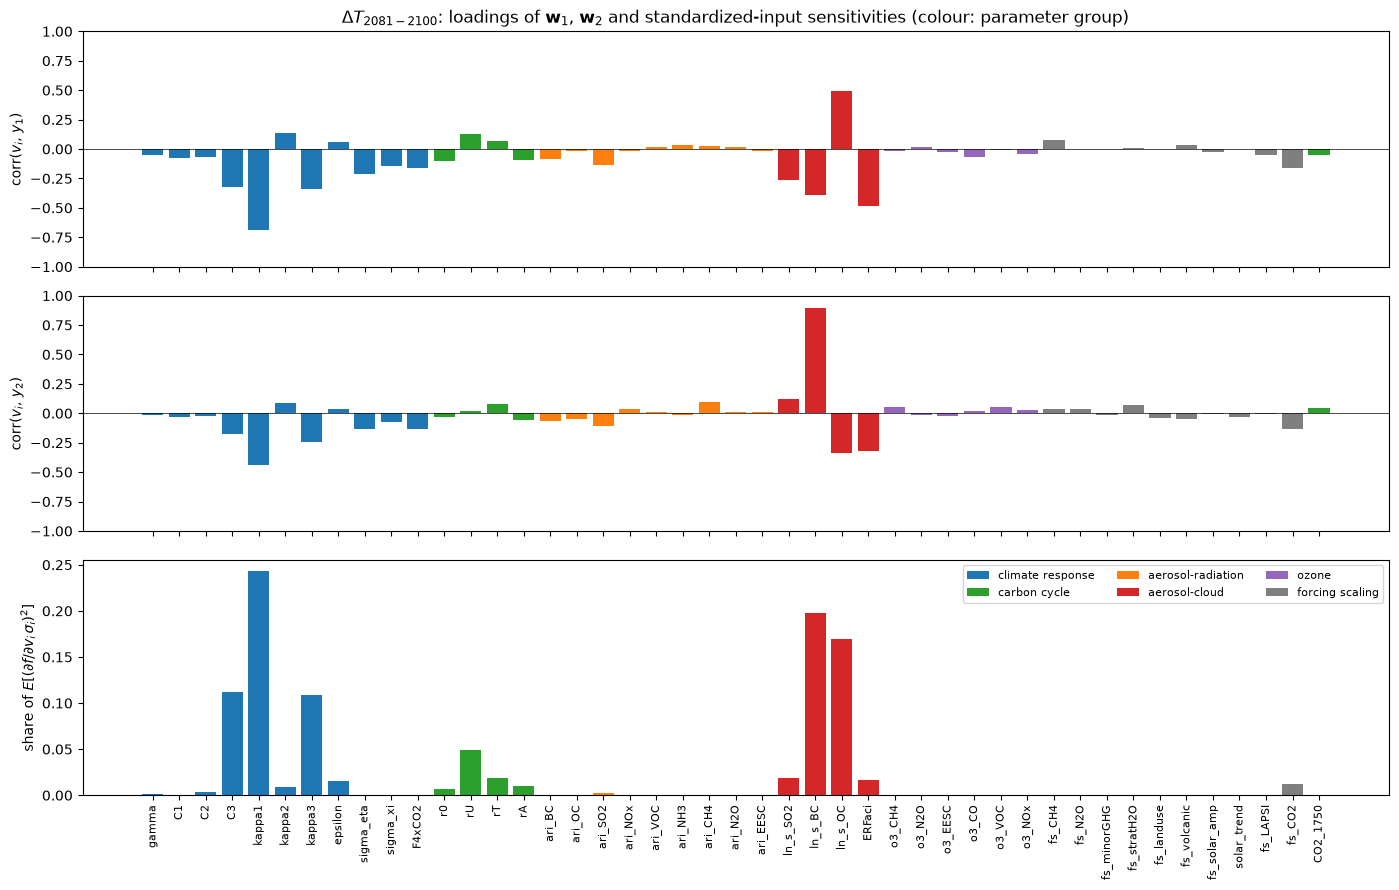

In [10]:
Sig = np.cov(V.T)
L = np.linalg.cholesky(Sig)
sd_v = np.sqrt(np.diag(Sig))
def loadings(w):
    """corr(v_i, w^T z) under the linear map z = L^{-1}(v - mean): (L w)_i / sd_i (independent of the factor L)."""
    return (L @ w) / sd_v
def emp_corr(w):
    y = Z @ w
    return np.array([np.corrcoef(V[:, i], y)[0, 1] for i in range(45)])
qd = 'dT_ssp245_2081-2100'
sq = np.mean((Gv[qd] * sd_v)**2, axis=0)   # E[(df/dv_i sd_i)^2], standardized-input sensitivity
W = sub[qd].W
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
cols = [GCOL[g] for g in fd.GROUP]
for k in range(2):
    axes[k].bar(range(45), loadings(W[:, k]), color=cols)
    axes[k].axhline(0, color='k', lw=.5); axes[k].set_ylim(-1, 1)
    axes[k].set_ylabel(f'corr($v_i$, $y_{k + 1}$)')
axes[2].bar(range(45), sq / sq.sum(), color=cols); axes[2].set_ylabel(r'share of $E[(\partial f/\partial v_i\,\sigma_i)^2]$')
axes[2].set_xticks(range(45)); axes[2].set_xticklabels(fd.SHORT_V, rotation=90, fontsize=8)
axes[0].set_title(r'$\Delta T_{2081-2100}$: loadings of $\mathbf{w}_1$, $\mathbf{w}_2$ and standardized-input sensitivities (colour: parameter group)')
for g, c in GCOL.items():
    axes[2].bar([0], [0], color=c, label=g)
axes[2].legend(fontsize=8, ncol=3)
fig.tight_layout(); plt.close(fig)
for k in range(2):
    l, e = loadings(W[:, k]), emp_corr(W[:, k])
    o = np.argsort(-np.abs(l))[:8]
    print(f'w{k + 1} loadings (formula / sample):', ', '.join(f'{fd.SHORT_V[i]} {l[i]:+.2f}/{e[i]:+.2f}' for i in o))
for k in (2, 3):
    l = loadings(W[:, k])
    o = np.argsort(-np.abs(l))[:6]
    print(f'w{k + 1} loadings:', ', '.join(f'{fd.SHORT_V[i]} {l[i]:+.2f}' for i in o))
je, jg, jk = (fd.SHORT_V.index(n) for n in ('sigma_eta', 'gamma', 'kappa1'))
print(f'sigma_eta (zero gradient): w1 loading {loadings(W[:, 0])[je]:+.2f}; corr with gamma {np.corrcoef(V[:, je], V[:, jg])[0, 1]:+.3f}, '
      f'with kappa1 {np.corrcoef(V[:, je], V[:, jk])[0, 1]:+.3f}; w1 loading of gamma {loadings(W[:, 0])[jg]:+.2f}')
o = np.argsort(-sq)[:8]
print('shares of E[(df/dv_i sd_i)^2]:', ', '.join(f'{fd.SHORT_V[i]} {sq[i] / sq.sum():.3f}' for i in o))
for g in GCOL:
    print(f'   group {g:18s}: {sum(sq[j] for j in range(45) if fd.GROUP[j] == g) / sq.sum():.3f}')
fig

Along $\mathbf w_1$, the SSP2-4.5 warming increases with a lower feedback parameter $\kappa_1$ (loading −0.69), a more negative present-day ERFaci (−0.49), lower $\kappa_3$ and $C_3$ (−0.34, −0.32), and with the aerosol–cloud shape parameters ($\ln s_{\rm OC}$ +0.50, $\ln s_{\rm BC}$ −0.39, $\ln s_{\rm SO_2}$ −0.26); the formula and sample loadings agree to the printed digits. $\mathbf w_2$ is mostly $\ln s_{\rm BC}$ (+0.90), whose posterior is multimodal (Fig. 10, p. 8586), $\mathbf w_3$ the deep-ocean set $C_3$, $\kappa_3$, $\varepsilon$ (−0.81, +0.74, +0.60), and $\mathbf w_4$ mostly $\ln s_{\rm OC}$ (−0.76). By gradient size, the climate-response group carries 0.493 of $E[(\partial f/\partial v_i\,\sigma_i)^2]$ ($\kappa_1$ 0.243, $C_3$ 0.112, $\kappa_3$ 0.109), the aerosol–cloud group 0.403 ($\ln s_{\rm BC}$ 0.198, $\ln s_{\rm OC}$ 0.169), the carbon cycle 0.086, aerosol–radiation 0.004 and ozone 0.001. ERFaci itself is not among the eight largest gradient shares: its loading on $\mathbf w_1$ comes mostly from its posterior correlation with the climate-response parameters (next figure). The same holds for $\sigma_\eta$, whose gradient is zero: its loading of −0.21 only reflects its correlations within the climate-response sample (+0.803 with $\gamma$, +0.270 with $\kappa_1$), not a sensitivity.

corr(dT, y1) = 0.780, corr(dT, y2) = 0.397
dT_ssp245_2081-2100  LOO R^2: n=1 quadratic 0.6368, cubic 0.6360; n=2 quadratic 0.8515, cubic 0.8771; n=3 quadratic 0.8685; n=4 quadratic 0.9166
ECS                  LOO R^2: n=1 quadratic 0.9712, cubic 0.9829; n=2 quadratic 0.9818, cubic 0.9970; n=3 quadratic 0.9820; n=4 quadratic 0.9818
TCR                  LOO R^2: n=1 quadratic 0.8401, cubic 0.8380; n=2 quadratic 0.8942, cubic 0.8951; n=3 quadratic 0.9254; n=4 quadratic 0.9471
GMST_2003-2022       LOO R^2: n=1 quadratic -0.0005, cubic 0.0154; n=2 quadratic 0.2680, cubic 0.3934; n=3 quadratic 0.4016; n=4 quadratic 0.7712


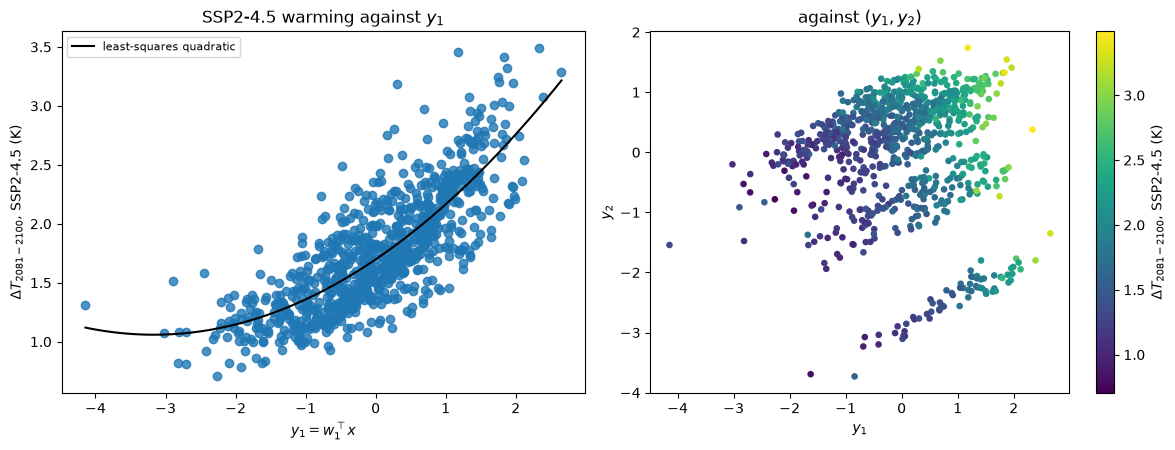

In [11]:
def fit(q, n, degree, key='v'):
    Xk, Gk = (V, Gv) if key == 'v' else (U, Gu)
    s = ac.active_subspace(space=spaces[key], X=Xk, f=F[q], grads=Gk[q], estimator='as', n=n)
    return ac.fit_surrogate(X=Xk, f=F[q], space=spaces[key], subspace=s, kind='poly', degree=degree)
sur = {(q, n, d): fit(q, n, d) for q in QN for n, d in ((1, 2), (1, 3), (2, 2), (2, 3), (3, 2), (4, 2))}
y = {q: Z @ sub[q].W[:, :2] for q in QN}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
ac.plotting.plot_sufficient_summary(sub[qd], X=V, f=F[qd], dims=1, qoi_label=QLAB[qd], ax=axes[0])
yy = np.linspace(y[qd][:, 0].min(), y[qd][:, 0].max(), 200)
c2 = np.polyfit(y[qd][:, 0], F[qd], 2)
axes[0].plot(yy, np.polyval(c2, yy), 'k-', lw=1.5, label='least-squares quadratic')
axes[0].legend(fontsize=8); axes[0].set_title(r'SSP2-4.5 warming against $y_1$')
sc = axes[1].scatter(y[qd][:, 0], y[qd][:, 1], c=F[qd], s=14, cmap='viridis')
axes[1].set_xlabel('$y_1$'); axes[1].set_ylabel('$y_2$'); fig.colorbar(sc, ax=axes[1], label=QLAB[qd])
axes[1].set_title(r'against $(y_1, y_2)$')
fig.tight_layout(); plt.close(fig)
print(f'corr(dT, y1) = {np.corrcoef(F[qd], y[qd][:, 0])[0, 1]:.3f}, corr(dT, y2) = {np.corrcoef(F[qd], y[qd][:, 1])[0, 1]:.3f}')
for q in QN:
    print(f'{q:20s} LOO R^2: n=1 quadratic {sur[q, 1, 2].loo_r_squared:.4f}, cubic {sur[q, 1, 3].loo_r_squared:.4f}; '
          f'n=2 quadratic {sur[q, 2, 2].loo_r_squared:.4f}, cubic {sur[q, 2, 3].loo_r_squared:.4f}; '
          f'n=3 quadratic {sur[q, 3, 2].loo_r_squared:.4f}; n=4 quadratic {sur[q, 4, 2].loo_r_squared:.4f}')
fig

The warming rises along $y_1$ (correlation 0.780) with a curved trend and a wide spread; a quadratic in $y_1$ has LOO $R^2$ 0.6368 and a cubic 0.6360. In $(y_1, y_2)$ the members fall into bands in $y_2$, the modes of $\ln s_{\rm BC}$, and the warming also increases with $y_2$ (correlation 0.397). LOO $R^2$ rises to 0.8515 for a quadratic in $(y_1, y_2)$, 0.8685 for $n = 3$ and 0.9166 for $n = 4$. For ECS a quadratic in $y_1$ already gives 0.9712 (a cubic in two variables 0.9970); TCR gives 0.8401 with $n = 1$ and 0.9471 with $n = 4$; GMST 2003–2022 gives −0.0005 with $n = 1$ and 0.7712 with $n = 4$.

ECS             w1 loadings: kappa1 -0.94, ERFaci -0.59, C3 -0.29, epsilon +0.24, kappa2 +0.23, sigma_eta -0.17 | |w1(dT) . w1(ECS)| = 0.669
TCR             w1 loadings: kappa1 -0.67, kappa3 -0.60, ERFaci -0.54, C2 -0.22, sigma_eta -0.21, epsilon -0.15 | |w1(dT) . w1(TCR)| = 0.691
GMST_2003-2022  w1 loadings: ln_s_BC +0.98, ln_s_OC -0.51, ln_s_SO2 +0.23, kappa1 -0.11, ari_CH4 +0.07, fs_CO2 -0.06 | |w1(dT) . w1(GMST_2003-2022)| = 0.430
dT_ssp245_2081-2100  share of trace(C) from the 42 members (5 %) with the largest |grad_z f|^2: 0.272
ECS                  share of trace(C) from the 42 members (5 %) with the largest |grad_z f|^2: 0.336
TCR                  share of trace(C) from the 42 members (5 %) with the largest |grad_z f|^2: 0.206
GMST_2003-2022       share of trace(C) from the 42 members (5 %) with the largest |grad_z f|^2: 0.416


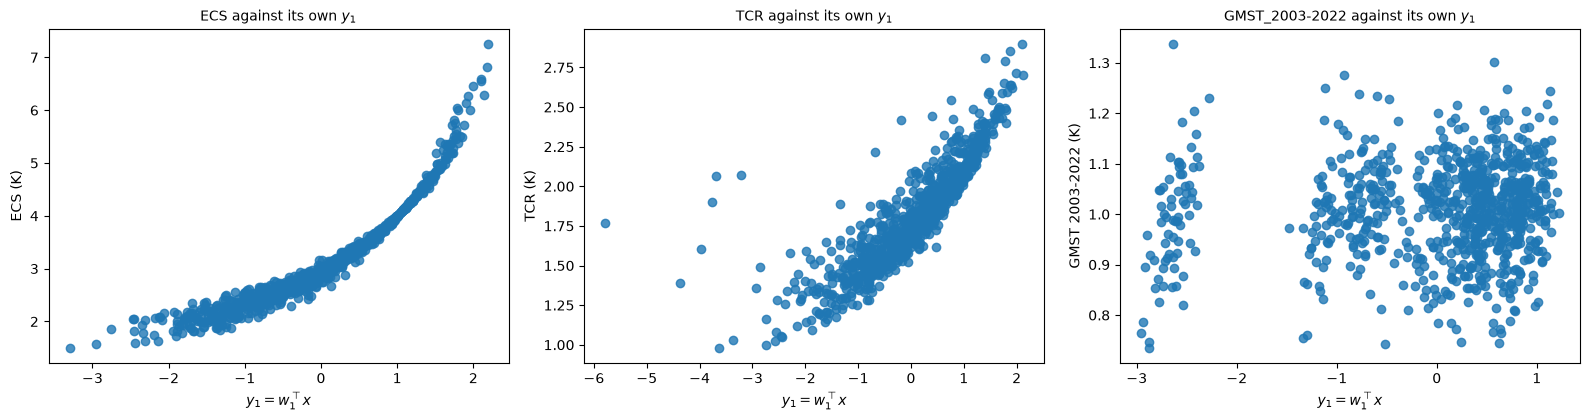

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for ax, q in zip(axes, QN[1:]):
    ac.plotting.plot_sufficient_summary(sub[q], X=V, f=F[q], dims=1, qoi_label=QLAB[q], ax=ax)
    ax.set_title(f'{q} against its own $y_1$', fontsize=10)
fig.tight_layout(); plt.close(fig)
for q in QN[1:]:
    l = loadings(sub[q].W[:, 0])
    o = np.argsort(-np.abs(l))[:6]
    print(f'{q:15s} w1 loadings:', ', '.join(f'{fd.SHORT_V[i]} {l[i]:+.2f}' for i in o),
          f'| |w1(dT) . w1({q})| = {abs(sub[qd].W[:, 0] @ sub[q].W[:, 0]):.3f}')
for q in QN:
    g2 = np.sum(space.grads_to_normalized(Gv[q])**2, axis=1)
    top = np.sort(g2)[::-1]
    print(f'{q:20s} share of trace(C) from the 42 members (5 %) with the largest |grad_z f|^2: {top[:42].sum() / g2.sum():.3f}')
fig

ECS rises steeply along its $y_1$ ($\kappa_1$ loading −0.94), and TCR along a mix of $\kappa_1$ and $\kappa_3$ (−0.67, −0.60). Both also load on ERFaci (−0.59 and −0.54) although neither depends on it: this is the correlation that the historical constraint leaves between strong aerosol cooling and high climate sensitivity, and it is why ERFaci loads on the warming's $\mathbf w_1$. Their $\mathbf w_1$ are at $|\cos|$ 0.669 and 0.691 to that of the warming. GMST 2003–2022 shows no trend along its $y_1$, which is $\ln s_{\rm BC}$ (+0.98), and its members fall into clusters; its gradient outer products are the most concentrated, with 0.416 of trace($\mathbf C$) from the 5 % of members with the largest gradients (0.272 for the warming).

In [13]:
# the evidence for the dimension of the dT subspace
lam = sub[qd].eigenvalues
print(f'dT: share of the trace left out by n = 1: {1 - lam[0] / lam.sum():.4f}, n = 2: {1 - lam[:2].sum() / lam.sum():.4f}, '
      f'n = 3: {1 - lam[:3].sum() / lam.sum():.4f}, n = 4: {1 - lam[:4].sum() / lam.sum():.4f}')
print('l1/l2, l2/l3, l3/l4, l4/l5:', ', '.join(f'{lam[i] / lam[i + 1]:.2f}' for i in range(4)))
lo, hi = np.percentile(sub[qd].bootstrap_eigenvalues, [2.5, 97.5], axis=0)[:, :5]
print('95 % bootstrap intervals of lambda1..5:', '; '.join(f'[{a:.3g}, {b:.3g}]' for a, b in zip(lo, hi)))
rat = sub[qd].bootstrap_eigenvalues[:, :4] / sub[qd].bootstrap_eigenvalues[:, 1:5]
lo, hi = np.percentile(rat, [2.5, 97.5], axis=0)
print('95 % bootstrap intervals of l1/l2, l2/l3, l3/l4, l4/l5:', '; '.join(f'[{a:.2f}, {b:.2f}]' for a, b in zip(lo, hi)))

dT: share of the trace left out by n = 1: 0.3380, n = 2: 0.2017, n = 3: 0.1068, n = 4: 0.0269
l1/l2, l2/l3, l3/l4, l4/l5: 4.86, 1.44, 1.19, 5.28
95 % bootstrap intervals of lambda1..5: [0.473, 0.561]; [0.0844, 0.134]; [0.0648, 0.0848]; [0.0528, 0.0698]; [0.00995, 0.0137]
95 % bootstrap intervals of l1/l2, l2/l3, l3/l4, l4/l5: [4.03, 5.87]; [1.14, 1.82]; [1.04, 1.44]; [4.19, 6.15]


10-fold CV R^2              dT_ssp245_2081-2100                  ECS                  TCR       GMST_2003-2022
OLS direction, quadratic                  0.917                0.955                0.872                0.635
OLS direction, cubic                      0.918                0.962                0.872                0.633
AS n = 1, quadratic                       0.635                0.970                0.839               -0.007
AS n = 2, quadratic                       0.852                0.981                0.896                0.265
AS n = 4, quadratic                       0.917                0.981                0.947                0.770
linear in all 45 z                        0.873                0.877                0.857                0.633
dT_ssp245_2081-2100  |cos(w1, w_ols)| 0.827; |cos| to span(w1..w4) 0.955; corr(f, w_ols^T z) 0.943; loadings kappa1 -0.87, ERFaci -0.69, C3 -0.31, sigma_eta -0.24, kappa3 -0.24
ECS                  |cos(w1, w_ols)| 0.990; |

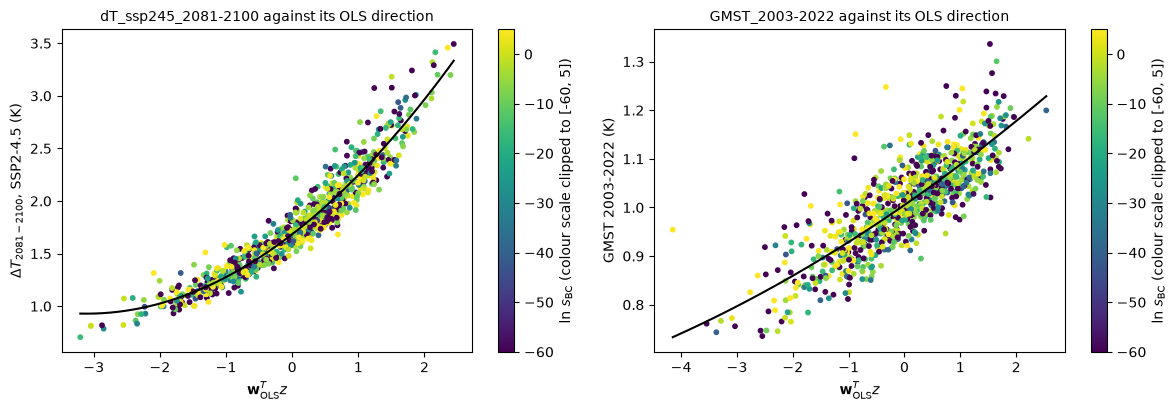

In [14]:
# a one-direction baseline: the least-squares (OLS) direction of f on z, against the gradient-based subspaces,
# by 10-fold cross-validation; every direction is re-estimated on the training folds (the whitening map, which
# uses the inputs only, is the one of the whole sample, as everywhere in this notebook)
def cv_r2(q, est, n, degree, K=10):
    idx = np.random.default_rng(SEED).permutation(len(V))
    pred = np.empty(len(V))
    for te in np.array_split(idx, K):
        tr = np.setdiff1d(idx, te)
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            s = None if est is None else ac.active_subspace(
                space=space, X=V[tr], f=F[q][tr], grads=Gv[q][tr] if est == 'as' else None, estimator=est, n=n)
            g = ac.fit_surrogate(X=V[tr], f=F[q][tr], space=space, subspace=s, kind='poly', degree=degree)
        pred[te] = ac.predict(g, V[te])
    return 1 - np.sum((F[q] - pred)**2) / np.sum((F[q] - F[q].mean())**2)
CV_CASES = [('OLS direction, quadratic', 'ols', 1, 2), ('OLS direction, cubic', 'ols', 1, 3),
            ('AS n = 1, quadratic', 'as', 1, 2), ('AS n = 2, quadratic', 'as', 2, 2),
            ('AS n = 4, quadratic', 'as', 4, 2), ('linear in all 45 z', None, None, 1)]
cvr = {(q, c[0]): cv_r2(q, *c[1:]) for q in QN for c in CV_CASES}
print(f"{'10-fold CV R^2':26s}" + ''.join(f'{q:>21s}' for q in QN))
for c in CV_CASES:
    print(f'{c[0]:26s}' + ''.join(f'{cvr[q, c[0]]:21.3f}' for q in QN))
# the OLS direction of the whole sample (signed so that f increases along it) against the gradient-based w1..w4
w_ols = {}
for q in QN:
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        w_ols[q] = ac.active_subspace(space=space, X=V, f=F[q], estimator='ols', n=1).W[:, 0]
    l = loadings(w_ols[q])
    o = np.argsort(-np.abs(l))[:5]
    print(f'{q:20s} |cos(w1, w_ols)| {abs(sub[q].W[:, 0] @ w_ols[q]):.3f}; |cos| to span(w1..w4) '
          f'{np.linalg.norm(sub[q].W[:, :4].T @ w_ols[q]):.3f}; corr(f, w_ols^T z) {np.corrcoef(F[q], Z @ w_ols[q])[0, 1]:.3f}; '
          'loadings ' + ', '.join(f'{fd.SHORT_V[i]} {l[i]:+.2f}' for i in o))
# where the largest gradients are: ln s_BC below -20 means no aerosol-cloud effect of BC
lnbc = V[:, fd.SHORT_V.index('ln_s_BC')]
tp, en, E = fd.load_emissions()
mid = (lnbc > -20) & (lnbc < 0)
print(f'ln s_BC: {np.mean(lnbc < -20):.3f} of the members below -20 (there s_BC A_BC < {np.exp(-20) * E[:, en.index("BC")].max():.0e} '
      f'in every year), {mid.mean():.3f} between -20 and 0; posterior sd {lnbc.std(ddof=1):.1f}')
for q in (qd, 'GMST_2003-2022'):
    g2 = np.sum(space.grads_to_normalized(Gv[q])**2, axis=1)
    big = np.argsort(-g2)[:42]
    print(f'{q:20s} the 42 members (5 %) with the largest |grad_z f|^2: {mid[big].mean():.3f} have -20 < ln s_BC < 0')
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, q in zip(axes, (qd, 'GMST_2003-2022')):
    yo = Z @ w_ols[q]
    sc = ax.scatter(yo, F[q], s=10, c=lnbc, cmap='viridis', vmin=-60, vmax=5)
    fig.colorbar(sc, ax=ax, label=r'ln $s_{\rm BC}$ (colour scale clipped to [-60, 5])')
    yy = np.linspace(yo.min(), yo.max(), 200)
    ax.plot(yy, np.polyval(np.polyfit(yo, F[q], 2), yy), 'k-', lw=1.5)
    ax.set_xlabel(r'$\mathbf{w}_{\rm OLS}^T z$'); ax.set_ylabel(QLAB[q])
    ax.set_title(f'{q} against its OLS direction', fontsize=10)
fig.tight_layout(); plt.close(fig)
fig

**A one-direction baseline.** The gradient-based eigenvectors are not the only candidate directions. A quadratic in the single least-squares direction $\mathbf w_{\rm OLS}$ of $f$ on $z$ has 10-fold cross-validated $R^2$ 0.917 for the SSP2-4.5 warming, the same as a quadratic in the four-dimensional active subspace (0.917) and well above a quadratic in $\mathbf w_1$ (0.635), a quadratic in $(y_1, y_2)$ (0.852) and a linear function of all 45 inputs (0.873); a cubic in $\mathbf w_{\rm OLS}$ adds nothing (0.918). So the warming is close to a one-dimensional ridge across the posterior, but along $\mathbf w_{\rm OLS}$, whose five largest loadings are $\kappa_1$ (−0.87), ERFaci (−0.69), $C_3$ (−0.31), $\sigma_\eta$ and $\kappa_3$ (−0.24 each; $\sigma_\eta$ again only by correlation), with no aerosol–cloud shape parameter among them (the figure shows the warming against it, with a least-squares quadratic). Its cosine with $\mathbf w_1$ is 0.827; it lies mostly inside the span of $\mathbf w_1, \dots, \mathbf w_4$ (cosine 0.955), which is why $n = 4$ recovers it. For GMST 2003–2022, $\mathbf w_1$ explains nothing (−0.007), $\mathbf w_{\rm OLS}$ gives 0.635 (cosine with $\mathbf w_1$ 0.105), no more than a linear function of all inputs (0.633), and the four-dimensional active subspace gives 0.770. For ECS, $\mathbf w_1$ is the better single direction (0.970 against 0.955), and for TCR the two are close (0.839 and 0.872).

The reason is in where the gradients are large. 0.415 of the members have $\ln s_{\rm BC} < -20$, where BC has no aerosol–cloud effect ($s_{\rm BC}A_{\rm BC} < 2\times10^{-8}$ in every year), and this mass sets the whitened scale of $\ln s_{\rm BC}$ (posterior sd 58.7). The members between −20 and 0, where the BC term switches on, are 0.401 of the sample but 0.667 of the 5 % with the largest gradients for the warming, and 0.929 for GMST. Large local gradients there dominate $\mathbf C$ (0.272 of its trace from 5 % of the members for the warming, 0.416 for GMST; above) without matching how much $f$ changes across the posterior. On a multimodal, heavy-tailed posterior like this one (kurtosis of $z$ up to 26.98), gradient-based eigenvalues need not rank directions by posterior variation, and the comparison with $\mathbf w_{\rm OLS}$ is the check that shows it.

**Dimension of the warming subspace.** By the gradient-based criteria, $n = 4$. The spectrum has two gaps, $\lambda_1/\lambda_2 = 4.86$ (95 % bootstrap interval [4.03, 5.87]) and $\lambda_4/\lambda_5 = 5.28$ ([4.19, 6.15]), while $\lambda_2/\lambda_3$ and $\lambda_3/\lambda_4$ are comparable (1.44 and 1.19; intervals [1.14, 1.82] and [1.04, 1.44]). $n = 1$ is well determined (subspace distance 0.045) but leaves out 0.3380 of the trace, and a quadratic in $y_1$ explains only 0.6368 (LOO $R^2$). $n = 2$ and 3 are not well determined (0.164, 0.281). $n = 4$ is well determined (0.042), leaves out 0.0269 of the trace, and a quadratic in its four active variables has LOO $R^2$ 0.9166. We therefore take $n = 4$ as the active-subspace dimension, with $y_1$ as the leading direction in the plots. This is not a minimal description of the warming: one direction, $\mathbf w_{\rm OLS}$, which the four-dimensional subspace nearly contains, does as well under cross-validation (0.917 for both). For ECS, $n = 1$ ($\lambda_1/\lambda_2 = 89.70$; $n = 2$ is exact). For TCR, $n = 1$ ($\lambda_1/\lambda_2 = 5.09$; the next ratio, 1.86, is comparable). For GMST 2003–2022, the quantity the posterior was fitted to, the gradient-based $\mathbf w_1$ explains nothing and the spectrum has no clear gap; a quadratic in one linear combination of the inputs, $\mathbf w_{\rm OLS}$, has cross-validated $R^2$ 0.635, and one in four active variables 0.770, so it has structure, but not structure that the leading gradient eigenvectors rank first.

### Why not $\beta$ itself

The cell repeats the estimate (no bootstrap) in the coordinates $u$, in which $\operatorname{asinh}\beta$ is an input and the shape parameters vary at fixed $\beta$. The signs of $\mathbf w_1$ are not set here.

In [15]:
# the same estimate in the coordinates u (beta itself, through asinh), for comparison
subu = {}
for q in QN:
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        subu[q] = ac.active_subspace(space=spaces['u'], X=U, f=F[q], grads=Gu[q], estimator='as', n=1)
Lu, sd_u = np.linalg.cholesky(np.cov(U.T)), U.std(axis=0, ddof=1)
for q in QN:
    lam = subu[q].eigenvalues
    l = (Lu @ subu[q].W[:, 0]) / sd_u
    o = np.argsort(-np.abs(l))[:3]
    print(f'u: {q:20s} lambda1 {lam[0]:.3g}, l1/l2 {lam[0] / lam[1]:.1f}; LOO R^2 quadratic in y1 '
          f'{fit(q, 1, 2, "u").loo_r_squared:.4f}; w1 loadings ' + ', '.join(f'{fd.SHORT[i]} {l[i]:+.2f}' for i in o))
sq_u = np.mean((Gu[qd] * sd_u)**2, axis=0)
print(f"u: dT share of E[(df/du_i sd_i)^2] from ln_s_BC {sq_u[25] / sq_u.sum():.3f}; "
      f"from the aerosol-cloud group {sum(sq_u[j] for j in range(24, 28)) / sq_u.sum():.3f}")
print(f"v: dT lambda1 {sub[qd].eigenvalues[0]:.3g}; u: dT lambda1 {subu[qd].eigenvalues[0]:.3g}")

u: dT_ssp245_2081-2100  lambda1 26.2, l1/l2 6.5; LOO R^2 quadratic in y1 -0.0037; w1 loadings ln_s_BC +1.00, ln_s_OC -0.39, asinh_beta +0.34
u: ECS                  lambda1 1.37, l1/l2 89.7; LOO R^2 quadratic in y1 0.9712; w1 loadings kappa1 +0.94, C3 +0.29, epsilon -0.24
u: TCR                  lambda1 0.172, l1/l2 5.1; LOO R^2 quadratic in y1 0.8401; w1 loadings kappa1 +0.67, kappa3 +0.60, C2 +0.22
u: GMST_2003-2022       lambda1 93.7, l1/l2 20.9; LOO R^2 quadratic in y1 -0.0006; w1 loadings ln_s_BC +1.00, ln_s_OC -0.35, asinh_beta +0.33
u: dT share of E[(df/du_i sd_i)^2] from ln_s_BC 0.804; from the aerosol-cloud group 0.986
v: dT lambda1 0.52; u: dT lambda1 26.2


In $u$, $\lambda_1$ of the SSP2-4.5 warming is 26.2 instead of 0.52, and $\lambda_1/\lambda_2 = 6.5$ looks like a clear one-dimensional subspace, but a quadratic in $y_1$ has LOO $R^2$ −0.0037: $\mathbf w_1$ is $\ln s_{\rm BC}$ (loading +1.00), and 0.804 of the gradient size comes from $\ln s_{\rm BC}$ alone (0.986 from the aerosol–cloud group). At fixed $\beta$, a change of $s_{\rm BC}$ changes the present-day aerosol–cloud forcing, which the prior sets through its trapezoid draw and the reweighting constrains (Table 6), so these large gradients point away from where the posterior has its mass. GMST 2003–2022 behaves the same way ($\lambda_1$ 93.7, LOO $R^2$ −0.0006). ECS and TCR, which do not depend on the aerosol parameters, are unchanged ($\lambda_1$ 1.37 and 0.172). For correlated inputs on a constrained posterior, the coordinates change the active subspace; here the coordinates in which the paper builds its prior give the more useful one.

### Comparison with the paper

The paper reports no active-subspace results. The cell prints the notebook values in the table (percentiles from the runs with internal variability, as in the paper).

In [16]:
for q in ['dT_ssp245_2081-2100', 'ECS', 'TCR', 'GMST_2003-2022', 'CO2_2022']:
    print(f'{q:20s} with internal variability 5/50/95 %: ' + ', '.join(f'{v:.3f}' for v in np.percentile(Fiv[q], [5, 50, 95])))
print('ERFaci 2005-2014 5/50/95 %:', ', '.join(f'{v:.3f}' for v in np.percentile(erfaci, [5, 50, 95])))
for q in QN:
    lam = sub[q].eigenvalues
    print(f'{q:20s} lambda1/lambda2 {lam[0] / lam[1]:.1f}; LOO R^2 quadratic in y1 {sur[q, 1, 2].loo_r_squared:.3f}')
for q in (qd, 'GMST_2003-2022'):
    print(f'{q:20s} 10-fold CV R^2: quadratic in the OLS direction {cvr[q, "OLS direction, quadratic"]:.3f}, '
          f'in AS n = 1 {cvr[q, "AS n = 1, quadratic"]:.3f}, in AS n = 4 {cvr[q, "AS n = 4, quadratic"]:.3f}')
print(f'notebook run time: {time.perf_counter() - t_start:.1f} s')

dT_ssp245_2081-2100  with internal variability 5/50/95 %: 1.064, 1.706, 2.658
ECS                  with internal variability 5/50/95 %: 2.012, 2.964, 4.987
TCR                  with internal variability 5/50/95 %: 1.312, 1.795, 2.377
GMST_2003-2022       with internal variability 5/50/95 %: 0.859, 1.027, 1.132
CO2_2022             with internal variability 5/50/95 %: 416.138, 417.034, 417.834
ERFaci 2005-2014 5/50/95 %: -1.663, -0.959, -0.344
dT_ssp245_2081-2100  lambda1/lambda2 4.9; LOO R^2 quadratic in y1 0.637
ECS                  lambda1/lambda2 89.7; LOO R^2 quadratic in y1 0.971
TCR                  lambda1/lambda2 5.1; LOO R^2 quadratic in y1 0.840
GMST_2003-2022       lambda1/lambda2 2.3; LOO R^2 quadratic in y1 -0.000
dT_ssp245_2081-2100  10-fold CV R^2: quadratic in the OLS direction 0.917, in AS n = 1 0.635, in AS n = 4 0.917
GMST_2003-2022       10-fold CV R^2: quadratic in the OLS direction 0.635, in AS n = 1 -0.007, in AS n = 4 0.770
notebook run time: 11.4 s


| quantity | paper (page) | notebook |
|---|---|---|
| SSP2-4.5 warming 2081–2100 rel. 1995–2014, 5/50/95 % (K) | 1.06, 1.71, 2.66 (Table 6, p. 8585) | 1.064, 1.706, 2.658 |
| ECS, 5/50/95 % (K) | 2.01, 2.96, 4.99 (Table 6) | 2.012, 2.964, 4.987 |
| TCR, 5/50/95 % (K) | 1.31, 1.79, 2.38 (Table 6) | 1.312, 1.795, 2.377 |
| GMST 2003–2022 rel. 1850–1900, 5/50/95 % (K) | 0.86, 1.03, 1.13 (Table 6) | 0.859, 1.027, 1.132 |
| CO$_2$ concentration 2022, 5/50/95 % (ppm) | 416.1, 417.0, 417.8 (Table 6) | 416.138, 417.034, 417.834 |
| ERFaci 2005–2014 rel. 1750, 5/50/95 % (W m$^{-2}$) | −1.66, −0.96, −0.35 (Table 6) | −1.663, −0.959, −0.344 (from $\beta D(s)$; within 0.0064 of Table 6, the 95 % value rounds to −0.34) |
| sampled parameters; posterior members | 45 (p. 8580); 841 (p. 8582) | 45; 841 |
| multimodal aerosol–cloud shape marginals | Fig. 10, pp. 8583, 8586 | bands in $(y_1, y_2)$; $\ln s_{\rm BC}$ dominates $\mathbf w_2$ |
| eigenvalue ratio $\lambda_1/\lambda_2$ (warming, ECS, TCR, GMST) | not reported | 4.9, 89.7, 5.1, 2.3 |
| active subspace dimension (warming) | not reported | 4 by the gradient eigenvalues (LOO $R^2$ 0.9166) |
| 10-fold CV $R^2$, quadratic in the OLS direction / in AS $n = 1$ / in AS $n = 4$ (warming) | not reported | 0.917 / 0.635 / 0.917 |
| the same for GMST 2003–2022 | not reported | 0.635 / −0.007 / 0.770 |
| LOO $R^2$, quadratic in $y_1$ (warming, ECS, TCR, GMST) | not reported | 0.637, 0.971, 0.840, −0.0005 (GMST: no trend along $\mathbf w_1$) |

### References

[1] C. Smith, D. P. Cummins, H.-B. Fredriksen, Z. Nicholls, M. Meinshausen, M. Allen, S. Jenkins, N. Leach, C. Mathison, and A.-I. Partanen. [fair-calibrate v1.4.1: calibration, constraining, and validation of the FaIR simple climate model for reliable future climate projections](https://doi.org/10.5194/gmd-17-8569-2024). *Geoscientific Model Development*, 17(23):8569–8592, 2024.

[2] C. Smith. [fair calibration data (v1.4.1)](https://doi.org/10.5281/zenodo.10566813). Zenodo, 2024. (The posterior and the fixed calibrations used here; cited as Smith, 2024 in [1], p. 8588.)

[3] N. J. Leach, S. Jenkins, Z. Nicholls, C. J. Smith, J. Lynch, M. Cain, T. Walsh, B. Wu, J. Tsutsui, and M. R. Allen. [FaIRv2.0.0: a generalized impulse response model for climate uncertainty and future scenario exploration](https://doi.org/10.5194/gmd-14-3007-2021). *Geoscientific Model Development*, 14(5):3007–3036, 2021.

[4] D. P. Cummins, D. B. Stephenson, and P. A. Stott. [Optimal estimation of stochastic energy balance model parameters](https://doi.org/10.1175/JCLI-D-19-0589.1). *Journal of Climate*, 33(18):7909–7926, 2020.

[5] Z. R. J. Nicholls, M. Meinshausen, J. Lewis, R. Gieseke, D. Dommenget, K. Dorheim, C.-S. Fan, J. S. Fuglestvedt, T. Gasser, U. Golüke, et al. [Reduced Complexity Model Intercomparison Project Phase 1: introduction and evaluation of global-mean temperature response](https://doi.org/10.5194/gmd-13-5175-2020). *Geoscientific Model Development*, 13(11):5175–5190, 2020. (RCMIP; the SSP2-4.5 emissions.)

[6] M. J. Gidden, S. Fujimori, M. van den Berg, D. Klein, S. J. Smith, D. P. van Vuuren, and K. Riahi. [A methodology and implementation of automated emissions harmonization for use in Integrated Assessment Models](https://doi.org/10.1016/j.envsoft.2018.04.002). *Environmental Modelling & Software*, 105:187–200, 2018. (aneris, the harmonisation.)

[7] P. G. Constantine. [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860). SIAM, 2015.

References [1], [3]–[7] were checked on Crossref; [2] is a Zenodo (DataCite) record and is given as printed in [1].

### Acknowledgments

The paper's financial support statement names the Natural Environment Research Council (grant NE/T009381/1) and the European Commission, Horizon Europe Framework Programme (grants 101081661 and 101003536) [1, p. 8589]. Its acknowledgements add a NERC/IIASA Collaborative Research Fellowship (NE/T009381/1) and WorldTrans (101081661) for C. Smith, ESM2025 (101003536) for Z. Nicholls, and the Met Office Hadley Centre Climate Programme funded by DSIT for C. Mathison and C. Smith [1, p. 8588].